# 01 · Primary model: stage 1 of the second-look pipeline

## Where this notebook sits
```
04_feature_engineering ─► features_*.parquet ──────────────┐
05_encode_scale ────────► model_ready_*.parquet ─┐         │
                                                 ▼         ▼
model_building/01_primary_model   Stage 1: logistic regression decides first
model_building/02_lightgbm        LightGBM (+ calibration), trained on everyone
model_building/03_second_look     Stage 2: applicants REJECTED by stage 1 get a second look from LightGBM
```

## Read this first
**The idea.** A bank usually already has a simple, trusted scoring model that makes the first decision. In this pipeline that is
the **primary model**: a **logistic regression** binary classifier (1 = will default, 0 = will repay).
- It gives every applicant a **probability of default (PD)**.
- **PD under 20% → approved** straight away (20% is the break-even point: +$2,000 per repaid loan, −$8,000 per default).
- **PD 20% or more → rejected** by stage 1. Those applicants are **not** declined yet: notebook 03 sends them to LightGBM for a **second look**.

**Why logistic regression as the primary model?** It's the industry-standard credit scorecard, it's fully explainable (every
feature has one weight), and the challenge requires it as the baseline to beat.

**Input:** `data/processed/model_ready_{fit,valid,test}.parquet` (scaled, imputed, one-hot data from notebook 05). Logistic
regression needs scaled inputs, unlike tree models.
**Output** (`artifacts/`): `primary_model.joblib` (the trained model) and stage-1 PDs and decisions for every applicant.

In [1]:
# Setup: libraries, paths, the week split and the shared scoring rules.

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from policy_metrics import CUTOFF, evaluate_decisions, evaluate_scores   # shared scoring rules (same folder)

warnings.filterwarnings("ignore", message="Overriding the parameters from Reference Dataset")

ROOT = Path.cwd().parent.parent          # notebooks/model_building -> repo root
PROCESSED = ROOT / "data" / "processed"
ART = Path.cwd() / "artifacts"
ART.mkdir(exist_ok=True)

SEED = 42
TUNE_START_WEEK = 68                     # weeks 0-67 train, 68-79 tune, 80-91 valid (scored once)
VALID_START_WEEK = 80

import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

## 1. Load the scaled data

`model_ready_fit` = weeks 0-79, `model_ready_valid` = weeks 80-91, `model_ready_test` = weeks 92-107 (no labels).
`case_id`, `target`, `WEEK_NUM` and `thin_file` are kept beside the features but are **not** model inputs.

In [2]:
# Load notebook 05's model-ready tables and separate the bookkeeping columns from the 106 model inputs.
fit_df = pd.read_parquet(PROCESSED / "model_ready_fit.parquet")
val_df = pd.read_parquet(PROCESSED / "model_ready_valid.parquet")
test_df = pd.read_parquet(PROCESSED / "model_ready_test.parquet")

META = ["case_id", "target", "WEEK_NUM", "thin_file"]
FEATURES = [c for c in fit_df.columns if c not in META]

X_fit, y_fit, week_fit = fit_df[FEATURES].to_numpy(np.float32), fit_df["target"].to_numpy(), fit_df["WEEK_NUM"].to_numpy()
X_val, y_val, thin_val = val_df[FEATURES].to_numpy(np.float32), val_df["target"].to_numpy(), val_df["thin_file"].to_numpy()
X_test = test_df[FEATURES].to_numpy(np.float32)
TR, TU = week_fit < TUNE_START_WEEK, week_fit >= TUNE_START_WEEK
print(f"{len(FEATURES)} model inputs | fit {len(fit_df):,} rows (weeks 0-79) | valid {len(val_df):,} | test {len(test_df):,}")

106 model inputs | fit 869,559 rows (weeks 0-79) | valid 130,441 | test 200,000


## 2. Choose the regularization strength without overfitting

Logistic regression has one main setting, `C`: smaller `C` = stronger penalty on large weights = simpler model. Each value is
trained on weeks 0-67 and scored on weeks 68-79 (LogLoss). Near-ties (within 0.0003) go to the **simplest** (smallest `C`), the
same rule as notebook 02.

In [3]:
# Try four regularization strengths on train -> tune weeks; keep the simplest among the near-best.
TIE_TOLERANCE = 0.0003
c_scores = {}
for C in [0.01, 0.1, 1.0, 10.0]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X_fit[TR], y_fit[TR])
    c_scores[C] = log_loss(y_fit[TU], m.predict_proba(X_fit[TU])[:, 1])
c_table = pd.Series(c_scores, name="tune LogLoss").to_frame()
BEST_C = min(c for c, s in c_scores.items() if s <= min(c_scores.values()) + TIE_TOLERANCE)
print(f"chosen C = {BEST_C}")
c_table.round(5)

chosen C = 0.01


,tune LogLoss
0.01,0.40183
0.10,0.40183
1.00,0.40183
10.00,0.40183


**What this shows:** every `C` scores the same to 5 decimal places, so the penalty strength doesn't matter here (1M rows is plenty
of data for 106 weights). The strongest penalty is kept because it's the safest choice.

## 3. Train the primary model and score the validation weeks

The chosen setting is retrained on all fit weeks (0-79) and scored once on weeks 80-91.

In [4]:
# Retrain on weeks 0-79, then produce stage-1 PDs and approve/reject decisions for validation and test.
t = time.time()
primary = LogisticRegression(C=BEST_C, max_iter=1000).fit(X_fit, y_fit)
print(f"trained in {time.time() - t:.0f}s")

pd_val = primary.predict_proba(X_val)[:, 1]
approve_val = pd_val < CUTOFF

pd.DataFrame({"Primary model (logistic regression)": {**evaluate_scores(y_val, pd_val, thin_val),
                                                      **evaluate_decisions(y_val, approve_val, thin_val)}}).T.round(3)

trained in 4s


,AUC,AUC thin,AUC est,LogLoss,Brier,Pred-actual thin pp,Pred-actual est pp,Approval %,Default % approved,Profit $M,Approved repayers est %,Approved repayers thin %,Inclusion gap pp,Accuracy,F1
Primary model (logistic regression),0.76,0.708,0.786,0.398,0.124,6.408,-0.047,60.479,8.317,92.17,78.1,40.165,37.935,0.678,0.433


**What this shows:** the primary model ranks applicants reasonably (AUC ≈ 0.76) and approves ~60% of them, but it treats thin-file
applicants harshly: it **over-predicts their risk by ~6 points**, approves only ~40% of thin-file applicants who would repay, and
leaves an inclusion gap of ~38 points. This is the "naïve single-threshold" situation the challenge asks us to improve.

## 4. Who does stage 1 reject?

These are the applicants that notebook 03 will send to LightGBM for a second look.

In [5]:
# Profile the rejected group: size, thin-file share, real default rate, and how many would have repaid.
rejected = ~approve_val
thin = thin_val == 1
profile = pd.DataFrame({
    "applicants": [rejected.sum(), (rejected & thin).sum(), (rejected & ~thin).sum()],
    "% of their segment rejected": [rejected.mean() * 100, rejected[thin].mean() * 100, rejected[~thin].mean() * 100],
    "actual default rate %": [y_val[rejected].mean() * 100, y_val[rejected & thin].mean() * 100, y_val[rejected & ~thin].mean() * 100],
    "would have repaid": [(rejected & (y_val == 0)).sum(), (rejected & thin & (y_val == 0)).sum(), (rejected & ~thin & (y_val == 0)).sum()],
}, index=["all rejected", "thin-file", "established"])
profile.round(1)

,applicants,% of their segment rejected,actual default rate %,would have repaid
all rejected,51551,39.5,31.2,35473
thin-file,25301,64.9,26.0,18714
established,26250,28.7,36.2,16759


**What this shows:** about 4 in 10 applicants are rejected, and **thin-file applicants make up about half of them** although they're
only 30% of all applicants. Roughly **two thirds of the rejected would actually have repaid**: a large pool of good customers for
the second look to find.

## 5. What drives the primary model

Because inputs are scaled, the weights can be compared: a bigger positive weight pushes the PD up (riskier), negative pushes it down.
This explainability is the main reason banks keep a logistic-regression scorecard.

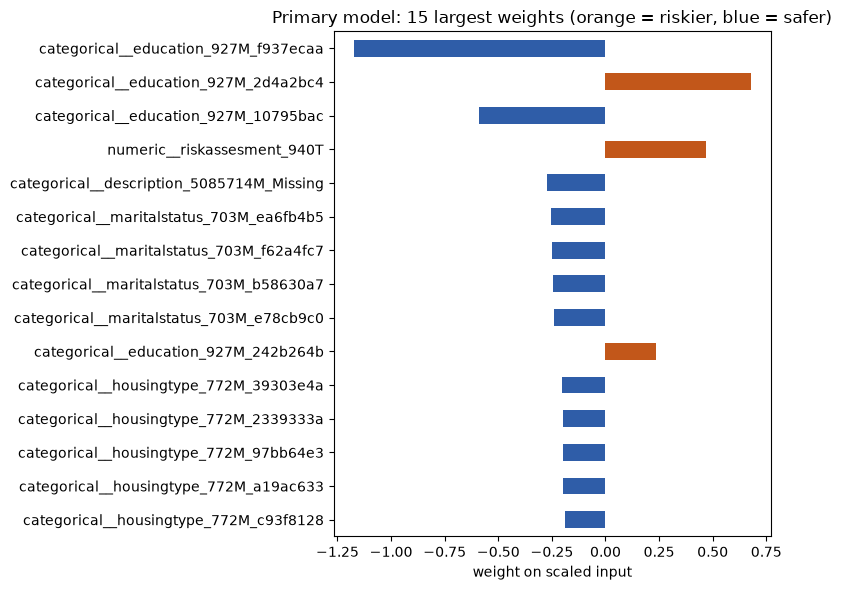

In [6]:
# Top 15 weights by size (scaled inputs, so weights are comparable).
coefs = pd.Series(primary.coef_[0], index=FEATURES)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
ax = top[::-1].plot.barh(figsize=(8, 6), color=["#C2571A" if v > 0 else "#2F5DA8" for v in top[::-1]])
ax.set(title="Primary model: 15 largest weights (orange = riskier, blue = safer)", xlabel="weight on scaled input")
plt.tight_layout(); plt.show()

## 6. Save stage-1 outputs for notebook 03

| File | Contents |
|---|---|
| `primary_model.joblib` | the trained logistic regression and its input column list (load with `joblib.load`) |
| `primary_predictions_{fit,valid,test}.parquet` | `case_id`, `WEEK_NUM`, `thin_file`, (`target`), `pd_primary`, `primary_approve` |

The fit-week file is needed to train the "specialist" second-look model in notebook 03 on the people stage 1 rejects.

In [7]:
# Save the model (pickle-style joblib file) and stage-1 decisions for every split.
joblib.dump({"model": primary, "features": FEATURES, "cutoff": CUTOFF, "C": BEST_C}, ART / "primary_model.joblib")

def save_stage1(df, X, name):
    p = primary.predict_proba(X)[:, 1]
    cols = [c for c in META if c in df]
    out = df[cols].reset_index(drop=True).assign(pd_primary=p, primary_approve=p < CUTOFF)
    out.to_parquet(ART / f"primary_predictions_{name}.parquet", index=False)
    return f"{name}: {len(out):,} rows, {out['primary_approve'].mean():.1%} approved by stage 1"

for df, X, name in [(fit_df, X_fit, "fit"), (val_df, X_val, "valid"), (test_df, X_test, "test")]:
    print(save_stage1(df, X, name))

fit: 869,559 rows, 59.9% approved by stage 1
valid: 130,441 rows, 60.5% approved by stage 1
test: 200,000 rows, 60.5% approved by stage 1


## 7. Conclusions
- The primary model is a solid, explainable scorecard (AUC ≈ 0.76), but on its own it is **unfair to thin-file applicants**: an
  inclusion gap of ~38 points, because it over-estimates their risk.
- It rejects about **4 in 10 applicants**, half of them thin-file, and most of the rejected would have repaid.
- **Next:** notebook 02 builds LightGBM; notebook 03 gives everyone stage 1 rejects a **second look** with it.